# Enterprise tool plans with DPO

One `Qwen2.5-1.5B-Instruct` LoRA serves six company tool catalogs. It reads the catalog, policy, request, and observations, then emits one JSON plan (`{goal, steps, stop_when}`) without executing tools.

Checker priority: `format` -> `empty` -> `catalog` -> `policy` -> `grounding` -> `selection`.

In [1]:
# Colab install. Skip if you already have recent transformers / trl / peft.
%pip install -q -U transformers trl peft datasets accelerate matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.2/948.2 kB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 112.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 13.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [11]:
%pip install -q -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 41.7 MB/s eta 0:00:00


In [2]:
import os

import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer
from trl import DPOConfig, DPOTrainer

os.environ["TOKENIZERS_PARALLELISM"] = "false"

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
# If the T4 runs out of memory, use "Qwen/Qwen2.5-0.5B-Instruct" and rerun from this cell.
SEED = 7
MAX_NEW_TOKENS = 180
BATCH_SIZE = 8
PAIRS_PATH = "enterprise_pairs.jsonl"
ADAPTER_DIR = "enterprise_dpo_lora"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# T4 is compute capability 7.5 (no hardware bf16 tensor cores). Only use bf16 on Ampere+ (cc >= 8).
BF16 = DEVICE.type == "cuda" and torch.cuda.get_device_capability(0)[0] >= 8
FP16 = DEVICE.type == "cuda" and not BF16
DTYPE = torch.bfloat16 if BF16 else torch.float16 if FP16 else torch.float32

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    cc = torch.cuda.get_device_capability(0)
    print(f"GPU: {props.name} (cc {cc[0]}.{cc[1]}) | VRAM {props.total_memory / (1024 ** 3):.1f} GiB")
    print(f"dtype: {DTYPE} | bf16={BF16} fp16={FP16}")
else:
    print("No GPU. In Colab: Runtime → Change runtime type → T4 GPU, then rerun.")


Device: cuda
GPU: Tesla T4 (cc 7.5) | VRAM 14.6 GiB
dtype: torch.float16 | bf16=False fp16=True


## 1. Catalogs and policy checker

A gated action (`issue_refund`, `transfer`, `wire`, `change_flight`, `refund_ticket`, `reset_password`, `issue_payout`, `reroute`, `file_damage_claim`) is legal only when the required evidence is already in `observations`.

In [3]:
import json
import re
from collections import Counter, defaultdict
from copy import deepcopy

TOKEN_RE = re.compile(
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|[A-Z]{2,}-\d+"
    r"|[A-Z]\d{1,6}"
    r"|\d+"
)

GATED = {
    "northwind": {"issue_refund"},
    "harbor": {"transfer", "wire"},
    "brightline": {"change_flight", "refund_ticket"},
    "lumen": {"reset_password"},
    "cedar": {"issue_payout"},
    "parcel": {"reroute", "file_damage_claim"},
}

TRAIN_PER_COMPANY = 90
EVAL_PER_COMPANY = 16

SYSTEM = (
    "You are the planning stage of a tool-using agent. "
    "You do not execute tools. You write a JSON plan that the executor will follow. "
    "Use only tools from this company's catalog. "
    "Every id, email, amount, and code in the plan must already appear in the user message, the policy, or the observations. "
    "If a required argument is missing or policy blocks the requested action, call ask_user. "
    "Do not call a gated tool before its required evidence is in the observations. "
    "Always include at least one step in steps. "
    "Output one JSON object and nothing else."
)

COMPANIES = {
    "northwind": {
        "name": "Northwind Retail",
        "tools": ["lookup_order", "lookup_customer", "check_inventory", "issue_refund", "ask_user"],
        "catalog": [
            "- lookup_order(order_id): returns status, total_usd, items, or not_found",
            "- lookup_customer(email): returns customer_id, name, order_ids",
            "- check_inventory(sku): returns units_available",
            "- issue_refund(order_id, reason): refund an order",
            "- ask_user(question): ask the user a question or confirm how to proceed",
        ],
        "policy": (
            "issue_refund is allowed only when observations show status is delivered or returned, "
            "total_usd is a number <= 50, and the lookup did not return not_found. "
            "If that evidence is missing, look the order up or ask the user."
        ),
    },
    "harbor": {
        "name": "Harbor Bank",
        "tools": ["lookup_account", "check_balance", "transfer", "wire", "open_dispute", "ask_user"],
        "catalog": [
            "- lookup_account(account_id): returns owner, balance_usd, status, or not_found",
            "- check_balance(account_id): returns balance_usd",
            "- transfer(from_account, to_account, amount_usd): move money between accounts at this bank",
            "- wire(from_account, amount_usd, beneficiary): send a wire",
            "- open_dispute(account_id, reason): open a dispute",
            "- ask_user(question): ask the user a question or confirm how to proceed",
        ],
        "policy": (
            "transfer and wire are allowed only when observations show balance_usd greater than or equal to the amount "
            "and the amount is <= 1000, and the account was found. "
            "A wire or transfer above 1000 needs a person, not the tool. "
            "If the balance is missing, look the account up or ask the user."
        ),
    },
    "brightline": {
        "name": "Brightline Air",
        "tools": ["lookup_pnr", "change_flight", "refund_ticket", "check_baggage", "ask_user"],
        "catalog": [
            "- lookup_pnr(pnr): returns fare_rule, status, passenger, or not_found",
            "- change_flight(pnr, new_flight): change a flight",
            "- refund_ticket(pnr, reason): refund a ticket",
            "- check_baggage(pnr): returns baggage status",
            "- ask_user(question): ask the user a question or confirm how to proceed",
        ],
        "policy": (
            "change_flight is allowed only when observations show fare_rule changeable. "
            "refund_ticket is allowed only when fare_rule is refundable. "
            "Otherwise look the PNR up or ask the user. Do not change or refund first."
        ),
    },
    "lumen": {
        "name": "Lumen IT",
        "tools": ["lookup_user", "verify_identity", "reset_password", "check_outage", "escalate", "ask_user"],
        "catalog": [
            "- lookup_user(email): returns user_type, identity_verified, or not_found",
            "- verify_identity(email): start identity verification",
            "- reset_password(email): reset a password",
            "- check_outage(service): returns outage status for a service",
            "- escalate(email, reason): escalate a shared mailbox or a request that cannot be reset",
            "- ask_user(question): ask the user a question or confirm how to proceed",
        ],
        "policy": (
            "reset_password is allowed only when observations show user_type employee and identity_verified true. "
            "A shared_mailbox is escalated, not reset. "
            "If identity is missing, look the user up or verify identity. Do not reset first."
        ),
    },
    "cedar": {
        "name": "Cedar Insurance",
        "tools": ["lookup_policy", "check_coverage", "file_claim", "assign_adjuster", "issue_payout", "ask_user"],
        "catalog": [
            "- lookup_policy(policy_id): returns status or not_found",
            "- check_coverage(policy_id): returns coverage_confirmed",
            "- file_claim(policy_id, reason): open a claim on an active policy",
            "- assign_adjuster(claim_id): assign an adjuster to a claim",
            "- issue_payout(claim_id, amount_usd): pay a claim",
            "- ask_user(question): ask the user a question or confirm how to proceed",
        ],
        "policy": (
            "issue_payout is allowed only when observations show coverage_confirmed true, a claim_id, "
            "and amount_usd <= 1000. Otherwise look the policy up, check coverage, file the claim, or ask the user. "
            "Do not pay first."
        ),
    },
    "parcel": {
        "name": "ParcelPath",
        "tools": ["track_shipment", "reroute", "file_damage_claim", "schedule_pickup", "ask_user"],
        "catalog": [
            "- track_shipment(tracking_id): returns status or not_found",
            "- reroute(tracking_id, destination): reroute a shipment",
            "- file_damage_claim(tracking_id, reason): file a damage claim",
            "- schedule_pickup(address_id, destination): schedule a pickup",
            "- ask_user(question): ask the user a question or confirm how to proceed",
        ],
        "policy": (
            "reroute is allowed only when observations show status in_transit. "
            "file_damage_claim is allowed only when status is delivered. "
            "If status is missing, track the shipment first. Do not reroute or file damage first."
        ),
    },
}

ENTITIES = {
    "train": {
        "northwind": {
            "orders": ["A110", "A120", "A130", "A140", "B210", "B220", "B230", "C310"],
            "emails": ["amy@northwind.example", "bob@northwind.example", "cara@northwind.example", "dan@northwind.example"],
            "skus": ["MUG-11", "MUG-12", "DESK-13", "LAMP-17"],
        },
        "harbor": {
            "accounts": ["ACCT-110", "ACCT-120", "ACCT-130", "ACCT-140", "ACCT-150", "ACCT-160"],
            "payees": ["ACCT-210", "ACCT-220", "ACCT-230", "ACCT-240", "ACCT-250", "ACCT-260"],
            "beneficiaries": ["BEN-11", "BEN-12", "BEN-13", "BEN-14", "BEN-15", "BEN-16"],
        },
        "brightline": {
            "pnrs": ["PNR-110", "PNR-120", "PNR-130", "PNR-140", "PNR-150", "PNR-160"],
            "flights": ["FL-21", "FL-22", "FL-23", "FL-24", "FL-25", "FL-26"],
        },
        "lumen": {
            "emails": ["amy@lumen.example", "bob@lumen.example", "cara@lumen.example", "dan@lumen.example"],
            "services": ["VPN-11", "VPN-12", "SSO-13", "SSO-14"],
        },
        "cedar": {
            "policies": ["POL-110", "POL-120", "POL-130", "POL-140", "POL-150", "POL-160"],
            "claims": ["CLM-110", "CLM-120", "CLM-130", "CLM-140", "CLM-150", "CLM-160"],
        },
        "parcel": {
            "tracking": ["SHP-110", "SHP-120", "SHP-130", "SHP-140", "SHP-150", "SHP-160"],
            "docks": ["DOCK-21", "DOCK-22", "DOCK-23", "DOCK-24", "DOCK-25", "DOCK-26"],
            "addresses": ["ADDR-11", "ADDR-12", "ADDR-13", "ADDR-14"],
        },
    },
    "eval": {
        "northwind": {
            "orders": ["Z910", "Z920", "Z930", "Z940"],
            "emails": ["noa@northwind.example", "zed@northwind.example"],
            "skus": ["VASE-91", "DESK-92"],
        },
        "harbor": {
            "accounts": ["ACCT-910", "ACCT-920", "ACCT-930"],
            "payees": ["ACCT-980", "ACCT-970", "ACCT-960"],
            "beneficiaries": ["BEN-91", "BEN-92", "BEN-93"],
        },
        "brightline": {
            "pnrs": ["PNR-910", "PNR-920", "PNR-930"],
            "flights": ["FL-91", "FL-92", "FL-93"],
        },
        "lumen": {
            "emails": ["ivy@lumen.example", "rex@lumen.example"],
            "services": ["VPN-91", "SSO-92"],
        },
        "cedar": {
            "policies": ["POL-910", "POL-920", "POL-930"],
            "claims": ["CLM-910", "CLM-920", "CLM-930"],
        },
        "parcel": {
            "tracking": ["SHP-910", "SHP-920", "SHP-930"],
            "docks": ["DOCK-91", "DOCK-92", "DOCK-93"],
            "addresses": ["ADDR-91", "ADDR-92"],
        },
    },
}


def _step(tool, args, because):
    return {"tool": tool, "args": args, "because": because}


def plan_text(goal, steps, stop_when):
    return json.dumps({"goal": goal, "steps": steps, "stop_when": stop_when}, indent=2)


SCHEMA_HINT = (
    'Return one JSON object matching this exact schema (with at least one step in "steps"):\n'
    '{\n'
    '  "goal": "<short goal>",\n'
    '  "steps": [\n'
    '    {"tool": "<tool_name>", "args": {"<arg_name>": "<value>"}, "because": "<reason>"}\n'
    '  ],\n'
    '  "stop_when": "<when to stop>"\n'
    '}'
)


def task_message(company_id, user, observations):
    company = COMPANIES[company_id]
    obs = "(none)" if observations is None else json.dumps(observations)
    catalog = "\n".join(company["catalog"])
    return (
        f"Company: {company['name']}\n\n"
        f"Tool catalog:\n{catalog}\n\n"
        f"Policy:\n{company['policy']}\n\n"
        f"Observations:\n{obs}\n\n"
        f"User:\n{user}\n\n"
        f"{SCHEMA_HINT}"
    )


def messages_for(company_id, user, observations):
    return [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": task_message(company_id, user, observations)},
    ]


def extract_json(text):
    raw = text.strip()
    fence = re.search(r"```(?:json)?\s*(\{.*\})\s*```", raw, re.S)
    if fence:
        raw = fence.group(1)
    start = raw.find("{")
    end = raw.rfind("}")
    if start < 0 or end <= start:
        return None
    try:
        return json.loads(raw[start:end + 1])
    except json.JSONDecodeError:
        return None


def _strings(obj):
    if isinstance(obj, dict):
        out = []
        for key, value in obj.items():
            if key == "because":
                continue
            out.extend(_strings(value))
        return out
    if isinstance(obj, list):
        out = []
        for value in obj:
            out.extend(_strings(value))
        return out
    if isinstance(obj, str):
        return [obj]
    if isinstance(obj, bool) or obj is None:
        return []
    if isinstance(obj, (int, float)):
        return [str(obj)]
    return []


def _num(value):
    return isinstance(value, (int, float)) and not isinstance(value, bool)


def evidence_allows(company_id, tool, observations, args):
    obs = observations if isinstance(observations, dict) else None
    if obs is None or obs.get("not_found") is True:
        return False
    args = args or {}
    if company_id == "northwind" and tool == "issue_refund":
        total = obs.get("total_usd")
        return obs.get("status") in {"delivered", "returned"} and _num(total) and total <= 50
    if company_id == "harbor" and tool in {"transfer", "wire"}:
        balance = obs.get("balance_usd")
        amount = args.get("amount_usd")
        return _num(balance) and _num(amount) and amount <= 1000 and balance >= amount
    if company_id == "brightline" and tool == "change_flight":
        return obs.get("fare_rule") == "changeable"
    if company_id == "brightline" and tool == "refund_ticket":
        return obs.get("fare_rule") == "refundable"
    if company_id == "lumen" and tool == "reset_password":
        return obs.get("user_type") == "employee" and obs.get("identity_verified") is True
    if company_id == "cedar" and tool == "issue_payout":
        amount = args.get("amount_usd")
        return obs.get("coverage_confirmed") is True and bool(obs.get("claim_id")) and _num(amount) and amount <= 1000
    if company_id == "parcel" and tool == "reroute":
        return obs.get("status") == "in_transit"
    if company_id == "parcel" and tool == "file_damage_claim":
        return obs.get("status") == "delivered"
    return False


def analyze_plan(company_id, user, observations, plan_or_text, gold_steps):
    """Independent violation buckets. Pair filtering uses the first non-empty bucket."""
    company = COMPANIES[company_id]
    context = task_message(company_id, user, observations)
    plan = extract_json(plan_or_text) if isinstance(plan_or_text, str) else plan_or_text
    result = {
        "format": [],
        "empty": [],
        "catalog": [],
        "policy": [],
        "grounding": [],
        "selection": [],
        "pred_tools": [],
        "plan": None,
    }
    if not isinstance(plan, dict) or not isinstance(plan.get("steps"), list):
        result["format"].append("output is not a JSON plan with a steps list")
        return result
    result["plan"] = plan
    if len(plan["steps"]) == 0:
        result["empty"].append("steps list is empty")
    allowed_tokens = set(TOKEN_RE.findall(context))
    for index, step in enumerate(plan["steps"]):
        if not isinstance(step, dict):
            result["format"].append(f"step {index} is not an object")
            continue
        tool = step.get("tool")
        result["pred_tools"].append(tool)
        if tool not in company["tools"]:
            result["catalog"].append(f"step {index} uses unknown tool {tool!r}")
        args = step.get("args") if isinstance(step.get("args"), dict) else {}
        if tool in GATED[company_id] and not evidence_allows(company_id, tool, observations, args):
            result["policy"].append(f"step {index} uses {tool} without policy evidence")
    blob = "\n".join(_strings(plan))
    for token in TOKEN_RE.findall(blob):
        if token not in allowed_tokens:
            result["grounding"].append(f"ungrounded token {token!r}")
    pred = [(step.get("tool"), step.get("args")) for step in plan["steps"] if isinstance(step, dict)]
    gold = [(step.get("tool"), step.get("args")) for step in gold_steps]
    if pred != gold:
        result["selection"].append("tools or arguments differ from the legal plan")
    for key in ("empty", "catalog", "policy", "grounding", "selection"):
        deduped = []
        seen = set()
        for item in result[key]:
            if item not in seen:
                seen.add(item)
                deduped.append(item)
        result[key] = deduped
    return result


def primary_violation(analysis):
    for key in ("format", "empty", "catalog", "policy", "grounding", "selection"):
        if analysis[key]:
            return key
    return None


def args_for(tool, slots):
    """Grounded args for a tool, or None when a required slot is absent."""
    need = {
        "lookup_order": ["order_id"],
        "lookup_customer": ["email"],
        "check_inventory": ["sku"],
        "issue_refund": ["order_id", "reason"],
        "lookup_account": ["account_id"],
        "check_balance": ["account_id"],
        "transfer": ["from_account", "to_account", "amount_usd"],
        "wire": ["from_account", "amount_usd", "beneficiary"],
        "open_dispute": ["account_id", "reason"],
        "lookup_pnr": ["pnr"],
        "change_flight": ["pnr", "new_flight"],
        "refund_ticket": ["pnr", "reason"],
        "check_baggage": ["pnr"],
        "lookup_user": ["email"],
        "verify_identity": ["email"],
        "reset_password": ["email"],
        "check_outage": ["service"],
        "escalate": ["email", "reason"],
        "lookup_policy": ["policy_id"],
        "check_coverage": ["policy_id"],
        "file_claim": ["policy_id", "reason"],
        "assign_adjuster": ["claim_id"],
        "issue_payout": ["claim_id", "amount_usd"],
        "track_shipment": ["tracking_id"],
        "reroute": ["tracking_id", "destination"],
        "file_damage_claim": ["tracking_id", "reason"],
        "schedule_pickup": ["address_id", "destination"],
        "ask_user": [],
    }[tool]
    if tool == "ask_user":
        return {"question": "What should I do next?"}
    args = {}
    for key in need:
        if key not in slots or slots[key] is None:
            return None
        args[key] = slots[key]
    return args


## 2. Preference pairs

540 train pairs (90/company) and 96 held-out eval prompts (16/company) with disjoint entity IDs. Each row pairs the legal plan (`chosen`) against one checker-verified near miss (`rejected`): `policy_breach`, `empty_steps`, `wrong_tool`, `foreign_tool`, `extra_tool`, `invented_arg`, or `unnecessary_ask`.

In [4]:
def _case(company_id, split, family, user, observations, goal, stop_when, steps, slots, breach_step=None):
    return {
        "company_id": company_id,
        "split": split,
        "family": family,
        "user": user,
        "observations": observations,
        "goal": goal,
        "stop_when": stop_when,
        "steps": steps,
        "slots": slots,
        "breach_step": breach_step,
    }


def _refund_breach(slots):
    args = args_for("issue_refund", slots)
    if args is None:
        return None
    return _step("issue_refund", args, "refund without the evidence the policy requires")


def _money_breach(tool, slots):
    args = args_for(tool, slots)
    if args is None:
        return None
    return _step(tool, args, "move money without the evidence the policy requires")


def build_cases(split):
    ent = ENTITIES[split]
    cases = []

    nw = ent["northwind"]
    for index, oid in enumerate(nw["orders"]):
        reason = ["arrived broken", "wrong item", "missing part"][index % 3]
        slots = {"order_id": oid, "reason": reason}
        user = f"Refund order {oid}. Reason: {reason}."
        breach = _refund_breach(slots)
        cases.append(_case(
            "northwind", split, "refund_no_obs", user, None,
            f"Look up order {oid} before any refund",
            "Stop after the lookup. Do not refund until the policy evidence is in the observations.",
            [_step("lookup_order", {"order_id": oid}, "status and total are not in the observations")],
            slots, breach,
        ))
        cases.append(_case(
            "northwind", split, "refund_allowed", user,
            {"order_id": oid, "status": "delivered", "total_usd": 20},
            f"Refund order {oid}",
            "Stop when the refund is issued.",
            [_step("issue_refund", {"order_id": oid, "reason": reason}, "delivered and total_usd 20 is within policy")],
            slots, None,
        ))
        cases.append(_case(
            "northwind", split, "refund_returned", user,
            {"order_id": oid, "status": "returned", "total_usd": 15},
            f"Refund order {oid}",
            "Stop when the refund is issued.",
            [_step("issue_refund", {"order_id": oid, "reason": reason}, "returned and total_usd 15 is within policy")],
            slots, None,
        ))
        cases.append(_case(
            "northwind", split, "refund_over_limit", user,
            {"order_id": oid, "status": "delivered", "total_usd": 80},
            f"Decide the refund for order {oid}",
            "Stop until the user answers. Do not refund over the limit.",
            [_step("ask_user", {"question": f"Order {oid} total is 80 USD, over the 50 USD limit. Should I stop?"}, "observations show total_usd 80")],
            slots, breach,
        ))
        cases.append(_case(
            "northwind", split, "refund_not_found", user,
            {"order_id": oid, "not_found": True},
            f"Resolve missing order {oid}",
            "Stop until the user confirms an id that exists.",
            [_step("ask_user", {"question": f"I could not find order {oid}. Can you confirm the id?"}, "observations say not_found")],
            slots, breach,
        ))
        cases.append(_case(
            "northwind", split, "refund_processing", user,
            {"order_id": oid, "status": "processing", "total_usd": 20},
            f"Decide the refund for order {oid}",
            "Stop until the user answers. Order is still processing.",
            [_step("ask_user", {"question": f"Order {oid} is still processing and cannot be refunded yet. Should I stop?"}, "observations show status processing")],
            slots, breach,
        ))

    for index, email in enumerate(nw["emails"]):
        slots = {"email": email}
        user = f"Who is the customer {email}?"
        cases.append(_case(
            "northwind", split, "customer_lookup", user, None,
            f"Look up customer {email}",
            "Stop after the customer lookup.",
            [_step("lookup_customer", {"email": email}, "the customer record is not in the observations")],
            slots, None,
        ))

    for sku in nw["skus"]:
        slots = {"sku": sku}
        user = f"How many units of {sku} are in stock?"
        cases.append(_case(
            "northwind", split, "inventory_check", user, None,
            f"Check inventory for {sku}",
            "Stop after the inventory check.",
            [_step("check_inventory", {"sku": sku}, "units are not in the observations")],
            slots, None,
        ))

    hb = ent["harbor"]
    for index, account in enumerate(hb["accounts"]):
        payee = hb["payees"][index]
        beneficiary = hb["beneficiaries"][index]
        amount = [40, 80, 120, 200, 40, 80][index]
        slots = {
            "account_id": account,
            "from_account": account,
            "to_account": payee,
            "amount_usd": amount,
            "beneficiary": beneficiary,
            "reason": "unknown charge",
        }
        transfer_user = f"Transfer {amount} USD from {account} to {payee}."
        cases.append(_case(
            "harbor", split, "transfer_no_obs", transfer_user, None,
            f"Look up account {account} before any transfer",
            "Stop after the lookup. Do not transfer until the balance is in the observations.",
            [_step("lookup_account", {"account_id": account}, "balance is not in the observations")],
            slots, _money_breach("transfer", slots),
        ))
        cases.append(_case(
            "harbor", split, "transfer_ok", transfer_user,
            {"account_id": account, "balance_usd": 500, "status": "open"},
            f"Transfer {amount} USD from {account} to {payee}",
            "Stop when the transfer is submitted.",
            [_step("transfer", {"from_account": account, "to_account": payee, "amount_usd": amount}, "balance covers the amount and the amount is within the daily limit")],
            slots, None,
        ))
        high = 1500 + index
        high_slots = dict(slots, amount_usd=high)
        high_user = f"Transfer {high} USD from {account} to {payee}."
        cases.append(_case(
            "harbor", split, "transfer_over_limit", high_user,
            {"account_id": account, "balance_usd": 5000, "status": "open"},
            f"Decide the transfer from {account}",
            "Stop until a person approves. Do not transfer above the daily limit.",
            [_step("ask_user", {"question": f"Transfer of {high} USD from {account} is over the 1000 USD daily limit. Should I stop?"}, "amount is over the daily limit")],
            high_slots, _money_breach("transfer", high_slots),
        ))
        poor_user = f"Transfer {amount} USD from {account} to {payee}."
        cases.append(_case(
            "harbor", split, "transfer_insufficient", poor_user,
            {"account_id": account, "balance_usd": 10, "status": "open"},
            f"Decide the transfer from {account}",
            "Stop until the user answers. The balance does not cover the transfer.",
            [_step("ask_user", {"question": f"Account {account} balance is 10 USD, under the {amount} USD transfer. Should I stop?"}, "balance does not cover the amount")],
            slots, _money_breach("transfer", slots),
        ))
        cases.append(_case(
            "harbor", split, "transfer_not_found", transfer_user,
            {"account_id": account, "not_found": True},
            f"Resolve missing account {account}",
            "Stop until the user confirms an account that exists.",
            [_step("ask_user", {"question": f"I could not find account {account}. Can you confirm the id?"}, "observations say not_found")],
            slots, _money_breach("transfer", slots),
        ))
        wire_user = f"Wire {amount} USD from {account} to {beneficiary}."
        cases.append(_case(
            "harbor", split, "wire_no_obs", wire_user, None,
            f"Look up account {account} before any wire",
            "Stop after the lookup. Do not wire until the balance is in the observations.",
            [_step("lookup_account", {"account_id": account}, "balance is not in the observations")],
            slots, _money_breach("wire", slots),
        ))
        cases.append(_case(
            "harbor", split, "wire_ok", wire_user,
            {"account_id": account, "balance_usd": 500, "status": "open"},
            f"Wire {amount} USD from {account} to {beneficiary}",
            "Stop when the wire is submitted.",
            [_step("wire", {"from_account": account, "amount_usd": amount, "beneficiary": beneficiary}, "balance covers the wire and the amount is within the daily limit")],
            slots, None,
        ))
        wire_high_user = f"Wire {high} USD from {account} to {beneficiary}."
        cases.append(_case(
            "harbor", split, "wire_over_limit", wire_high_user,
            {"account_id": account, "balance_usd": 5000, "status": "open"},
            f"Decide the wire from {account}",
            "Stop until a person approves. Do not wire above the daily limit.",
            [_step("ask_user", {"question": f"Wire of {high} USD from {account} is over the 1000 USD daily limit. Should I stop?"}, "amount is over the daily limit")],
            high_slots, _money_breach("wire", high_slots),
        ))
        bal_user = f"What is the balance of {account}?"
        cases.append(_case(
            "harbor", split, "balance_no_obs", bal_user, None,
            f"Check the balance of {account}",
            "Stop after the balance check.",
            [_step("check_balance", {"account_id": account}, "balance is not in the observations")],
            slots, None,
        ))
        dispute_user = f"Open a dispute on {account}. Reason: unknown charge."
        cases.append(_case(
            "harbor", split, "dispute", dispute_user, None,
            f"Open a dispute on {account}",
            "Stop when the dispute is open.",
            [_step("open_dispute", {"account_id": account, "reason": "unknown charge"}, "the account id and the reason are in the user message")],
            slots, None,
        ))

    bl = ent["brightline"]
    for index, pnr in enumerate(bl["pnrs"]):
        flight = bl["flights"][index]
        slots = {"pnr": pnr, "new_flight": flight, "reason": "trip cancelled"}
        change_user = f"Change {pnr} to flight {flight}."
        cases.append(_case(
            "brightline", split, "change_no_obs", change_user, None,
            f"Look up {pnr} before any change",
            "Stop after the lookup. Do not change the flight until the fare rule is in the observations.",
            [_step("lookup_pnr", {"pnr": pnr}, "fare_rule is not in the observations")],
            slots, _step("change_flight", {"pnr": pnr, "new_flight": flight}, "change without a fare rule"),
        ))
        cases.append(_case(
            "brightline", split, "change_ok", change_user,
            {"pnr": pnr, "fare_rule": "changeable", "status": "confirmed"},
            f"Change {pnr} to flight {flight}",
            "Stop when the flight is changed.",
            [_step("change_flight", {"pnr": pnr, "new_flight": flight}, "fare_rule is changeable")],
            slots, None,
        ))
        cases.append(_case(
            "brightline", split, "change_restricted", change_user,
            {"pnr": pnr, "fare_rule": "restricted", "status": "confirmed"},
            f"Decide the change for {pnr}",
            "Stop until the user answers. The fare rule does not allow a change.",
            [_step("ask_user", {"question": f"{pnr} fare rule is restricted. Should I stop the change to {flight}?"}, "fare_rule is restricted")],
            slots, _step("change_flight", {"pnr": pnr, "new_flight": flight}, "change a restricted fare"),
        ))
        refund_user = f"Refund ticket {pnr}. Reason: trip cancelled."
        cases.append(_case(
            "brightline", split, "refund_no_obs", refund_user, None,
            f"Look up {pnr} before any refund",
            "Stop after the lookup. Do not refund the ticket until the fare rule is in the observations.",
            [_step("lookup_pnr", {"pnr": pnr}, "fare_rule is not in the observations")],
            slots, _step("refund_ticket", {"pnr": pnr, "reason": "trip cancelled"}, "refund without a fare rule"),
        ))
        cases.append(_case(
            "brightline", split, "refund_ok", refund_user,
            {"pnr": pnr, "fare_rule": "refundable", "status": "confirmed"},
            f"Refund ticket {pnr}",
            "Stop when the ticket is refunded.",
            [_step("refund_ticket", {"pnr": pnr, "reason": "trip cancelled"}, "fare_rule is refundable")],
            slots, None,
        ))
        cases.append(_case(
            "brightline", split, "refund_restricted", refund_user,
            {"pnr": pnr, "fare_rule": "restricted", "status": "confirmed"},
            f"Decide the refund for {pnr}",
            "Stop until the user answers. The fare rule does not allow a refund.",
            [_step("ask_user", {"question": f"{pnr} fare rule is restricted. Should I stop the refund?"}, "fare_rule is restricted")],
            slots, _step("refund_ticket", {"pnr": pnr, "reason": "trip cancelled"}, "refund a restricted fare"),
        ))
        cases.append(_case(
            "brightline", split, "pnr_not_found", change_user,
            {"pnr": pnr, "not_found": True},
            f"Resolve missing PNR {pnr}",
            "Stop until the user confirms a PNR that exists.",
            [_step("ask_user", {"question": f"I could not find {pnr}. Can you confirm the PNR?"}, "observations say not_found")],
            slots, _step("change_flight", {"pnr": pnr, "new_flight": flight}, "change a missing PNR"),
        ))
        bag_user = f"Where is the baggage for {pnr}?"
        cases.append(_case(
            "brightline", split, "baggage", bag_user, None,
            f"Check baggage for {pnr}",
            "Stop after the baggage check.",
            [_step("check_baggage", {"pnr": pnr}, "baggage status is not in the observations")],
            {"pnr": pnr}, None,
        ))

    lm = ent["lumen"]
    for email in lm["emails"]:
        slots = {"email": email, "reason": "shared mailbox"}
        reset_user = f"Reset the password for {email}."
        cases.append(_case(
            "lumen", split, "reset_no_obs", reset_user, None,
            f"Look up {email} before any password reset",
            "Stop after the lookup. Do not reset until identity is in the observations.",
            [_step("lookup_user", {"email": email}, "user_type is not in the observations")],
            slots, _step("reset_password", {"email": email}, "reset without identity evidence"),
        ))
        cases.append(_case(
            "lumen", split, "reset_need_verify", reset_user,
            {"email": email, "user_type": "employee", "identity_verified": False},
            f"Verify identity for {email}",
            "Stop after identity verification. Do not reset yet.",
            [_step("verify_identity", {"email": email}, "the user is an employee and identity is not verified")],
            slots, _step("reset_password", {"email": email}, "reset before identity is verified"),
        ))
        cases.append(_case(
            "lumen", split, "reset_ok", reset_user,
            {"email": email, "user_type": "employee", "identity_verified": True},
            f"Reset the password for {email}",
            "Stop when the password is reset.",
            [_step("reset_password", {"email": email}, "employee and identity_verified")],
            slots, None,
        ))
        cases.append(_case(
            "lumen", split, "shared_mailbox", reset_user,
            {"email": email, "user_type": "shared_mailbox", "identity_verified": True},
            f"Escalate the shared mailbox {email}",
            "Stop when the shared mailbox is escalated. Do not reset it.",
            [_step("escalate", {"email": email, "reason": "shared mailbox"}, "shared_mailbox is not reset")],
            slots, _step("reset_password", {"email": email}, "reset a shared mailbox"),
        ))
        cases.append(_case(
            "lumen", split, "user_not_found", reset_user,
            {"email": email, "not_found": True},
            f"Resolve missing user {email}",
            "Stop until the user confirms an email that exists.",
            [_step("ask_user", {"question": f"I could not find {email}. Can you confirm the email?"}, "observations say not_found")],
            slots, _step("reset_password", {"email": email}, "reset a missing user"),
        ))
        verify_user = f"Start identity verification for {email}."
        cases.append(_case(
            "lumen", split, "verify_direct", verify_user, None,
            f"Verify identity for {email}",
            "Stop after starting identity verification.",
            [_step("verify_identity", {"email": email}, "the user asked to start identity verification")],
            slots, _step("reset_password", {"email": email}, "reset instead of verifying"),
        ))

    for service in lm["services"]:
        slots = {"service": service}
        user = f"Is {service} down?"
        cases.append(_case(
            "lumen", split, "outage", user, None,
            f"Check whether {service} is down",
            "Stop after the outage check.",
            [_step("check_outage", {"service": service}, "outage status is not in the observations")],
            slots, None,
        ))

    cd = ent["cedar"]
    for index, policy_id in enumerate(cd["policies"]):
        claim_id = cd["claims"][index]
        reason = "water damage"
        slots = {"policy_id": policy_id, "claim_id": claim_id, "amount_usd": 200, "reason": reason}
        file_user = f"File a claim on {policy_id}. Reason: {reason}."
        cases.append(_case(
            "cedar", split, "claim_no_obs", file_user, None,
            f"Look up policy {policy_id} before filing a claim",
            "Stop after the lookup. Do not file until the policy status is in the observations.",
            [_step("lookup_policy", {"policy_id": policy_id}, "policy status is not in the observations")],
            slots, _step("issue_payout", {"claim_id": claim_id, "amount_usd": 200}, "pay before coverage is confirmed"),
        ))
        cases.append(_case(
            "cedar", split, "claim_active", file_user,
            {"policy_id": policy_id, "status": "active"},
            f"File a claim on {policy_id}",
            "Stop when the claim is filed.",
            [_step("file_claim", {"policy_id": policy_id, "reason": reason}, "policy status is active")],
            slots, _step("issue_payout", {"claim_id": claim_id, "amount_usd": 200}, "pay before a covered claim exists"),
        ))
        cases.append(_case(
            "cedar", split, "claim_lapsed", file_user,
            {"policy_id": policy_id, "status": "lapsed"},
            f"Decide the claim on {policy_id}",
            "Stop until the user answers. A lapsed policy cannot take a new claim.",
            [_step("ask_user", {"question": f"Policy {policy_id} is lapsed. Should I stop the claim?"}, "policy status is lapsed")],
            slots, _step("issue_payout", {"claim_id": claim_id, "amount_usd": 200}, "pay on a lapsed policy"),
        ))
        pay_user = f"Pay 200 USD on claim {claim_id}."
        cases.append(_case(
            "cedar", split, "payout_no_obs", pay_user, None,
            f"Ask for the policy id or coverage before paying claim {claim_id}",
            "Stop until coverage is confirmed in the observations.",
            [_step("ask_user", {"question": f"Coverage for claim {claim_id} is not in the observations. What is the policy id?"}, "coverage is not confirmed")],
            slots, _step("issue_payout", {"claim_id": claim_id, "amount_usd": 200}, "pay without coverage evidence"),
        ))
        cases.append(_case(
            "cedar", split, "payout_ok", pay_user,
            {"claim_id": claim_id, "coverage_confirmed": True, "amount_usd": 200},
            f"Pay 200 USD on claim {claim_id}",
            "Stop when the payout is issued.",
            [_step("issue_payout", {"claim_id": claim_id, "amount_usd": 200}, "coverage is confirmed and the amount is within policy")],
            slots, None,
        ))
        cases.append(_case(
            "cedar", split, "payout_denied", pay_user,
            {"claim_id": claim_id, "coverage_confirmed": False, "amount_usd": 200},
            f"Decide the payout for claim {claim_id}",
            "Stop until the user answers. Coverage is not confirmed.",
            [_step("ask_user", {"question": f"Coverage for claim {claim_id} is not confirmed. Should I stop the payout?"}, "coverage_confirmed is false")],
            slots, _step("issue_payout", {"claim_id": claim_id, "amount_usd": 200}, "pay without coverage"),
        ))
        cov_user = f"Check coverage for {policy_id}."
        cases.append(_case(
            "cedar", split, "coverage_check", cov_user, None,
            f"Check coverage for {policy_id}",
            "Stop after the coverage check.",
            [_step("check_coverage", {"policy_id": policy_id}, "coverage is not in the observations")],
            slots, None,
        ))
        assign_user = f"Assign an adjuster to claim {claim_id}."
        cases.append(_case(
            "cedar", split, "assign_adjuster", assign_user, None,
            f"Assign an adjuster to claim {claim_id}",
            "Stop when the adjuster is assigned.",
            [_step("assign_adjuster", {"claim_id": claim_id}, "the claim id is in the user message")],
            slots, None,
        ))

    pp = ent["parcel"]
    for index, tracking in enumerate(pp["tracking"]):
        dock = pp["docks"][index]
        slots = {"tracking_id": tracking, "destination": dock, "reason": "crushed box"}
        track_user = f"Where is shipment {tracking}?"
        cases.append(_case(
            "parcel", split, "track", track_user, None,
            f"Track shipment {tracking}",
            "Stop after the tracking lookup.",
            [_step("track_shipment", {"tracking_id": tracking}, "status is not in the observations")],
            slots, _step("reroute", {"tracking_id": tracking, "destination": dock}, "reroute before status is known"),
        ))
        reroute_user = f"Reroute shipment {tracking} to {dock}."
        cases.append(_case(
            "parcel", split, "reroute_no_obs", reroute_user, None,
            f"Track shipment {tracking} before a reroute",
            "Stop after the tracking lookup. Do not reroute until status is in the observations.",
            [_step("track_shipment", {"tracking_id": tracking}, "status is not in the observations")],
            slots, _step("reroute", {"tracking_id": tracking, "destination": dock}, "reroute without status"),
        ))
        cases.append(_case(
            "parcel", split, "reroute_ok", reroute_user,
            {"tracking_id": tracking, "status": "in_transit"},
            f"Reroute shipment {tracking} to {dock}",
            "Stop when the shipment is rerouted.",
            [_step("reroute", {"tracking_id": tracking, "destination": dock}, "status is in_transit")],
            slots, None,
        ))
        cases.append(_case(
            "parcel", split, "reroute_delivered", reroute_user,
            {"tracking_id": tracking, "status": "delivered"},
            f"Decide the reroute for shipment {tracking}",
            "Stop until the user answers. A delivered shipment cannot be rerouted.",
            [_step("ask_user", {"question": f"Shipment {tracking} is delivered. Should I stop the reroute to {dock}?"}, "status is delivered")],
            slots, _step("reroute", {"tracking_id": tracking, "destination": dock}, "reroute a delivered shipment"),
        ))
        damage_user = f"File a damage claim for shipment {tracking}. Reason: crushed box."
        cases.append(_case(
            "parcel", split, "damage_ok", damage_user,
            {"tracking_id": tracking, "status": "delivered"},
            f"File a damage claim for shipment {tracking}",
            "Stop when the damage claim is filed.",
            [_step("file_damage_claim", {"tracking_id": tracking, "reason": "crushed box"}, "status is delivered")],
            slots, None,
        ))
        cases.append(_case(
            "parcel", split, "damage_in_transit", damage_user,
            {"tracking_id": tracking, "status": "in_transit"},
            f"Decide the damage claim for shipment {tracking}",
            "Stop until the user answers. Damage is filed only after delivery.",
            [_step("ask_user", {"question": f"Shipment {tracking} is in transit. Should I stop the damage claim?"}, "status is not delivered")],
            slots, _step("file_damage_claim", {"tracking_id": tracking, "destination": dock}, "file damage before delivery"),
        ))
        cases.append(_case(
            "parcel", split, "damage_no_obs", damage_user, None,
            f"Track shipment {tracking} before a damage claim",
            "Stop after the tracking lookup. Do not file damage until status is in the observations.",
            [_step("track_shipment", {"tracking_id": tracking}, "status is not in the observations")],
            slots, _step("file_damage_claim", {"tracking_id": tracking, "reason": "crushed box"}, "file damage without status"),
        ))

    for index, address in enumerate(pp["addresses"]):
        dock = pp["docks"][index]
        slots = {"address_id": address, "destination": dock}
        user = f"Schedule a pickup from {address} to {dock}."
        cases.append(_case(
            "parcel", split, "pickup", user, None,
            f"Schedule a pickup from {address} to {dock}",
            "Stop when the pickup is scheduled.",
            [_step("schedule_pickup", {"address_id": address, "destination": dock}, "the address and the destination are in the user message")],
            slots, None,
        ))
    return cases


MUTATIONS = (
    "policy_breach",
    "empty_steps",
    "wrong_tool",
    "foreign_tool",
    "extra_tool",
    "invented_arg",
    "unnecessary_ask",
)

EXPECTED = {
    "policy_breach": "policy",
    "empty_steps": "empty",
    "wrong_tool": "selection",
    "foreign_tool": "catalog",
    "extra_tool": "selection",
    "invented_arg": "grounding",
    "unnecessary_ask": "selection",
}


def _foreign_tool(case):
    pool = []
    own = set(COMPANIES[case["company_id"]]["tools"])
    for other in COMPANIES.values():
        for tool in other["tools"]:
            if tool not in own and tool != "ask_user" and tool not in pool:
                pool.append(tool)
    if not pool:
        return None
    tool = pool[sum(ord(ch) for ch in case["user"]) % len(pool)]
    return [_step(tool, {}, "use a tool this company does not have")]


def _args_are_grounded(case, args):
    context = task_message(case["company_id"], case["user"], case["observations"])
    allowed = set(TOKEN_RE.findall(context))
    return all(token in allowed for token in TOKEN_RE.findall("\n".join(_strings(args))))


def _safe_step(case, banned):
    company = COMPANIES[case["company_id"]]
    for tool in company["tools"]:
        if tool in GATED[case["company_id"]] or tool in banned:
            continue
        args = args_for(tool, case["slots"])
        if args is None or not _args_are_grounded(case, args):
            continue
        return _step(tool, args, "this tool does not answer the request")
    return None


def _wrong_steps(case):
    gold_tools = {step["tool"] for step in case["steps"]}
    step = _safe_step(case, gold_tools)
    if step is None:
        return None
    return [step]


def _extra_steps(case):
    gold_tools = {step["tool"] for step in case["steps"]}
    banned = set(gold_tools)
    step = _safe_step(case, banned)
    if step is None:
        return None
    return list(case["steps"]) + [step]


def _invent_steps(case):
    if not case["steps"]:
        return None
    steps = deepcopy(case["steps"])
    for step in steps:
        for key, value in list(step["args"].items()):
            if isinstance(value, str):
                step["args"][key] = "Q8"
                return steps
    return None


def _ask_steps(case):
    gold_tools = [step["tool"] for step in case["steps"]]
    if gold_tools == ["ask_user"]:
        return None
    return [_step("ask_user", {"question": "What should I do next?"}, "ask even though the next tool is determined")]


def mutate(case, name):
    if name == "empty_steps":
        return []
    if name == "foreign_tool":
        return _foreign_tool(case)
    if name == "wrong_tool":
        return _wrong_steps(case)
    if name == "extra_tool":
        return _extra_steps(case)
    if name == "invented_arg":
        return _invent_steps(case)
    if name == "policy_breach":
        if case["breach_step"] is None:
            return None
        breach = deepcopy(case["breach_step"])
        if not _args_are_grounded(case, breach["args"]):
            return None
        return [breach]
    if name == "unnecessary_ask":
        return _ask_steps(case)
    raise KeyError(name)


def _cap(rows, limit):
    """Keep `limit` rows, rotating families and mutation types so the tail is not dropped."""
    by_family = defaultdict(lambda: defaultdict(list))
    for row in rows:
        by_family[row["family"]][row["mutation"]].append(row)
    queues = {}
    for family_index, (family, by_mutation) in enumerate(by_family.items()):
        keys = [name for name in MUTATIONS if by_mutation[name]]
        if keys:
            shift = family_index % len(keys)
            keys = keys[shift:] + keys[:shift]
        queue = []
        while any(by_mutation.values()):
            for name in list(keys):
                bucket = by_mutation[name]
                if bucket:
                    queue.append(bucket.pop(0))
                else:
                    keys = [item for item in keys if by_mutation[item]]
        queues[family] = queue
    families = list(queues)
    kept = []
    while len(kept) < limit and families:
        for family in list(families):
            if len(kept) >= limit:
                break
            queue = queues[family]
            if queue:
                kept.append(queue.pop(0))
            if not queue:
                families = [item for item in families if queues[item]]
    return kept


def generate_pairs():
    dropped = Counter()
    grouped = defaultdict(list)
    seen = set()
    for split in ("train", "eval"):
        for case in build_cases(split):
            chosen = plan_text(case["goal"], case["steps"], case["stop_when"])
            chosen_analysis = analyze_plan(
                case["company_id"], case["user"], case["observations"], chosen, case["steps"]
            )
            if primary_violation(chosen_analysis) is not None:
                dropped["chosen_failed"] += 1
                dropped[f"chosen_failed:{case['family']}:{primary_violation(chosen_analysis)}"] += 1
                continue
            for name in MUTATIONS:
                steps = mutate(case, name)
                if steps is None:
                    dropped["not_applicable"] += 1
                    continue
                stop_when = False if name == "empty_steps" else case["stop_when"]
                rejected = plan_text(case["goal"], steps, stop_when)
                if rejected == chosen:
                    dropped["same_text"] += 1
                    continue
                analysis = analyze_plan(
                    case["company_id"], case["user"], case["observations"], rejected, case["steps"]
                )
                kind = primary_violation(analysis)
                if kind is None:
                    dropped["rejected_clean"] += 1
                    continue
                if kind != EXPECTED[name]:
                    dropped[f"wrong_category:{name}:{kind}"] += 1
                    continue
                key = (case["split"], case["company_id"], case["user"], json.dumps(case["observations"], sort_keys=True), rejected)
                if key in seen:
                    dropped["duplicate"] += 1
                    continue
                seen.add(key)
                grouped[(split, case["company_id"])].append({
                    "company": case["company_id"],
                    "family": case["family"],
                    "mutation": name,
                    "split": split,
                    "user": case["user"],
                    "observations": case["observations"],
                    "chosen": chosen,
                    "rejected": rejected,
                    "gold_tools": [step["tool"] for step in case["steps"]],
                })
    rows = []
    for split, limit in (("train", TRAIN_PER_COMPANY), ("eval", EVAL_PER_COMPANY)):
        for company_id in COMPANIES:
            rows.extend(_cap(grouped[(split, company_id)], limit))
    return rows, dropped


def id_strings(split):
    found = set()

    def walk(value):
        if isinstance(value, dict):
            for item in value.values():
                walk(item)
        elif isinstance(value, list):
            for item in value:
                walk(item)
        elif isinstance(value, str) and (TOKEN_RE.search(value) or "@" in value):
            found.add(value)

    walk(ENTITIES[split])
    return found


def assert_pairs(rows, dropped):
    assert len(rows) >= 500, len(rows)
    by_company = Counter(row["company"] for row in rows if row["split"] == "train")
    by_eval = Counter(row["company"] for row in rows if row["split"] == "eval")
    for company_id in COMPANIES:
        assert by_company[company_id] >= 80, (company_id, by_company[company_id])
        assert by_eval[company_id] >= 15, (company_id, by_eval[company_id])
        kinds = {row["mutation"] for row in rows if row["company"] == company_id and row["split"] == "train"}
        assert len(kinds) >= 5, (company_id, kinds)
    eval_ids = id_strings("eval")
    train_blob = json.dumps([row for row in rows if row["split"] == "train"])
    leaked = sorted(item for item in eval_ids if item in train_blob)
    assert not leaked, leaked
    for row in rows:
        gold = extract_json(row["chosen"])["steps"]
        assert len(gold) >= 1, ("empty chosen steps", row["family"])
        chosen_kind = primary_violation(analyze_plan(row["company"], row["user"], row["observations"], row["chosen"], gold))
        rejected_kind = primary_violation(analyze_plan(row["company"], row["user"], row["observations"], row["rejected"], gold))
        assert chosen_kind is None, (row["family"], chosen_kind)
        assert rejected_kind == EXPECTED[row["mutation"]], (row["mutation"], rejected_kind)
    return by_company, by_eval


wrote enterprise_pairs.jsonl
total 636 | train 540 | eval 96
train per company {'northwind': 90, 'harbor': 90, 'brightline': 90, 'lumen': 90, 'cedar': 90, 'parcel': 90}
eval per company {'northwind': 16, 'harbor': 16, 'brightline': 16, 'lumen': 16, 'cedar': 16, 'parcel': 16}
train mutations {'policy_breach': 43, 'wrong_tool': 85, 'foreign_tool': 94, 'extra_tool': 87, 'invented_arg': 89, 'empty_steps': 86, 'unnecessary_ask': 56}
eval mutations {'policy_breach': 9, 'wrong_tool': 19, 'foreign_tool': 22, 'extra_tool': 14, 'invented_arg': 11, 'empty_steps': 15, 'unnecessary_ask': 6}
dropped {}


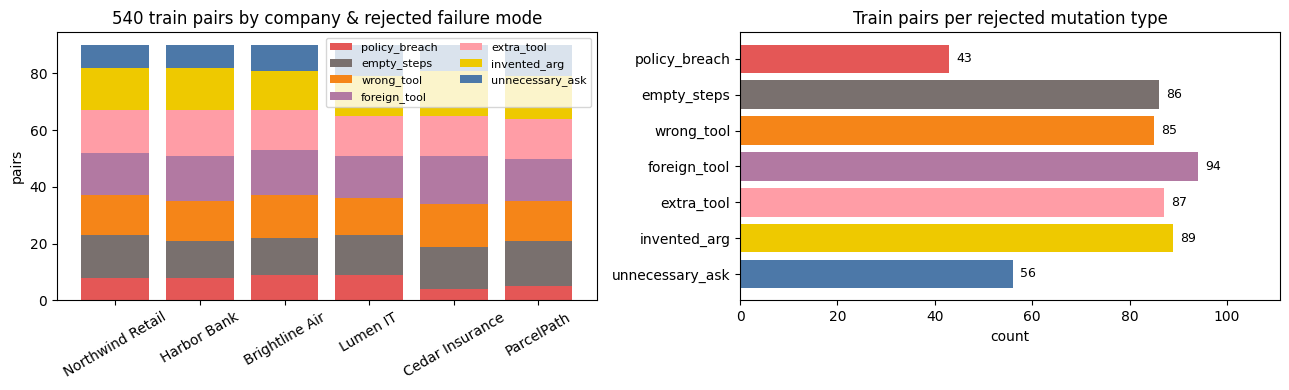


== northwind refund_no_obs policy_breach
USER Refund order A110. Reason: arrived broken.
OBS None
{
  "goal": "Look up order A110 before any refund",
  "steps": [
    {
      "tool": "lookup_order",
      "args": {
        "order_id": "A110"
      },
      "because": "status and total are not in the observations"
    }
  ],
  "stop_when": "Stop after the lookup. Do not refund until the policy evidence is in the observations."
}
--- rejected ---
{
  "goal": "Look up order A110 before any refund",
  "steps": [
    {
      "tool": "issue_refund",
      "args": {
        "order_id": "A110",
        "reason": "arrived broken"
      },
      "because": "refund without the evidence the policy requires"
    }
  ],
  "stop_when": "Stop after the lookup. Do not refund until the policy evidence is in the observations."
}

== harbor wire_ok empty_steps
USER Wire 40 USD from ACCT-110 to BEN-11.
OBS {'account_id': 'ACCT-110', 'balance_usd': 500, 'status': 'open'}
{
  "goal": "Wire 40 USD from ACCT-

In [5]:
def plot_pair_distribution(train_rows):
    companies = list(COMPANIES)
    company_names = [COMPANIES[c]["name"] for c in companies]
    colors = {
        "policy_breach": "#E45756",
        "empty_steps": "#79706E",
        "wrong_tool": "#F58518",
        "foreign_tool": "#B279A2",
        "extra_tool": "#FF9DA6",
        "invented_arg": "#EEC900",
        "unnecessary_ask": "#4C78A8",
    }
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))

    # Left: stacked bar of mutations per company
    bottoms = [0] * len(companies)
    for mutation in MUTATIONS:
        counts = [
            sum(1 for r in train_rows if r["company"] == c and r["mutation"] == mutation)
            for c in companies
        ]
        axes[0].bar(company_names, counts, bottom=bottoms, label=mutation, color=colors[mutation])
        bottoms = [b + c for b, c in zip(bottoms, counts)]
    axes[0].set_title("540 train pairs by company & rejected failure mode")
    axes[0].set_ylabel("pairs")
    axes[0].tick_params(axis="x", rotation=30)
    axes[0].legend(fontsize=8, loc="upper right", ncol=2)

    # Right: total counts per mutation across dataset
    totals = [sum(1 for r in train_rows if r["mutation"] == m) for m in MUTATIONS]
    bars = axes[1].barh(list(MUTATIONS), totals, color=[colors[m] for m in MUTATIONS])
    axes[1].invert_yaxis()
    axes[1].set_title("Train pairs per rejected mutation type")
    axes[1].set_xlabel("count")
    for bar, val in zip(bars, totals):
        axes[1].text(val + 1.5, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9)
    axes[1].set_xlim(0, max(totals) * 1.18)

    fig.tight_layout()
    plt.show()


rows, dropped = generate_pairs()
by_company, by_eval = assert_pairs(rows, dropped)
train_rows = [row for row in rows if row["split"] == "train"]
eval_rows = [row for row in rows if row["split"] == "eval"]

with open(PAIRS_PATH, "w", encoding="utf-8") as handle:
    for row in rows:
        handle.write(json.dumps(row) + "\n")

print("wrote", PAIRS_PATH)
print("total", len(rows), "| train", len(train_rows), "| eval", len(eval_rows))
print("train per company", dict(by_company))
print("eval per company", dict(by_eval))
print("train mutations", dict(Counter(row["mutation"] for row in train_rows)))
print("eval mutations", dict(Counter(row["mutation"] for row in eval_rows)))
print("dropped", {key: value for key, value in dropped.items() if key != "not_applicable"})

plot_pair_distribution(train_rows)

used = set()
for mutation in MUTATIONS:
    for row in train_rows:
        if row["mutation"] == mutation and row["company"] not in used:
            used.add(row["company"])
            print("\n==", row["company"], row["family"], row["mutation"])
            print("USER", row["user"])
            print("OBS", row["observations"])
            print(row["chosen"])
            print("--- rejected ---")
            print(row["rejected"])
            break


## 3. Evaluation metrics

`exact` (tool sequence + args), `tool F1`, `policy`, `wrong_seq`, `ungrounded`, `illegal`, and `empty`.

In [6]:
OUTCOME_ORDER = [
    "exact",
    "policy",
    "wrong_seq",
    "ungrounded",
    "illegal",
    "empty",
]

OUTCOME_LABELS = {
    "exact": "Exact match",
    "policy": "Policy breach",
    "wrong_seq": "Wrong tool / args",
    "ungrounded": "Ungrounded arg",
    "illegal": "Foreign / illegal",
    "empty": "Empty / unparsed",
}


def classify_outcome(analysis):
    if analysis["format"] or analysis["empty"]:
        return "empty"
    if analysis["catalog"]:
        return "illegal"
    if analysis["policy"]:
        return "policy"
    if analysis["grounding"]:
        return "ungrounded"
    if analysis["selection"]:
        return "wrong_seq"
    return "exact"


def tool_scores(row, text):
    gold = extract_json(row["chosen"])["steps"]
    analysis = analyze_plan(row["company"], row["user"], row["observations"], text, gold)
    pred = analysis["pred_tools"]
    gold_tools = [step["tool"] for step in gold]
    parsed = not analysis["format"]
    pred_set = set(pred) if parsed else set()
    gold_set = set(gold_tools)
    if not pred_set and not gold_set and parsed:
        precision, recall, f1 = 1.0, 1.0, 1.0
    else:
        tp = len(pred_set & gold_set)
        precision = tp / len(pred_set) if pred_set else 0.0
        recall = tp / len(gold_set) if gold_set else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0
    catalog = set(COMPANIES[row["company"]]["tools"])
    outcome = classify_outcome(analysis)
    return {
        "parsed": parsed,
        "empty": (not parsed) or bool(analysis["empty"]),
        "exact": outcome == "exact",
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "illegal": (not parsed) or any(tool not in catalog for tool in pred),
        "foreign": parsed and any(tool not in catalog and any(tool in COMPANIES[other]["tools"] for other in COMPANIES) for tool in pred),
        "policy": bool(analysis["policy"]),
        "ungrounded": bool(analysis["grounding"]),
        "wrong_seq": outcome == "wrong_seq",
        "outcome": outcome,
        "pred_tools": pred if parsed else [],
        "gold_tools": gold_tools,
    }



def summarize(rows, texts):
    scores = [tool_scores(row, text) for row, text in zip(rows, texts)]
    summary = {}
    gold_counts = {company_id: Counter() for company_id in COMPANIES}
    pred_counts = {company_id: Counter() for company_id in COMPANIES}
    outcomes = {company_id: Counter() for company_id in COMPANIES}
    buckets = {company_id: [] for company_id in COMPANIES}
    for row, score in zip(rows, scores):
        cid = row["company"]
        buckets[cid].append(score)
        outcomes[cid][score["outcome"]] += 1
        for tool in score["gold_tools"]:
            gold_counts[cid][tool] += 1
        for tool in score["pred_tools"]:
            pred_counts[cid][tool] += 1
    for company_id, items in buckets.items():
        count = len(items)

        def avg(key):
            return sum(item[key] for item in items) / count

        summary[company_id] = {
            "n": count,
            "exact": avg("exact"),
            "tool_precision": avg("precision"),
            "tool_recall": avg("recall"),
            "tool_f1": avg("f1"),
            "policy_rate": avg("policy"),
            "wrong_seq_rate": avg("wrong_seq"),
            "ungrounded_rate": avg("ungrounded"),
            "illegal_rate": avg("illegal"),
            "foreign_rate": avg("foreign"),
            "empty_rate": avg("empty"),
            "parse_rate": avg("parsed"),
            "outcomes": outcomes[company_id],
        }
    return summary, gold_counts, pred_counts, scores


def print_summary(title, summary):
    print(title)
    print(
        f"{'company':<12} {'n':>3} {'exact':>7} {'f1':>7} {'policy':>8} "
        f"{'wrong_seq':>10} {'unground':>9} {'illegal':>8} {'empty':>7}"
    )
    for company_id, row in summary.items():
        print(
            f"{company_id:<12} {row['n']:3d} {row['exact']:7.2f} {row['tool_f1']:7.2f} "
            f"{row['policy_rate']:8.2f} {row['wrong_seq_rate']:10.2f} "
            f"{row['ungrounded_rate']:9.2f} {row['illegal_rate']:8.2f} {row['empty_rate']:7.2f}"
        )
    n_all = sum(r["n"] for r in summary.values())
    if n_all:
        def overall(key):
            return sum(r[key] * r["n"] for r in summary.values()) / n_all
        print("-" * 78)
        print(
            f"{'OVERALL':<12} {n_all:3d} {overall('exact'):7.2f} {overall('tool_f1'):7.2f} "
            f"{overall('policy_rate'):8.2f} {overall('wrong_seq_rate'):10.2f} "
            f"{overall('ungrounded_rate'):9.2f} {overall('illegal_rate'):8.2f} {overall('empty_rate'):7.2f}"
        )


def plot_tool_counts(gold_counts, pred_counts, title):
    fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.5))
    for ax, company_id in zip(axes.ravel(), COMPANIES):
        labels = list(COMPANIES[company_id]["tools"])
        for tool in pred_counts[company_id]:
            if tool not in labels:
                labels.append(tool)
        x = list(range(len(labels)))
        ax.bar([i - 0.2 for i in x], [gold_counts[company_id][tool] for tool in labels], 0.4, label="gold", color="#4C78A8")
        ax.bar([i + 0.2 for i in x], [pred_counts[company_id][tool] for tool in labels], 0.4, label="model", color="#F58518")
        ax.set_title(COMPANIES[company_id]["name"])
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=40, ha="right", fontsize=8)
    axes[0][0].legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_rates(before, after):
    keys = ["exact", "tool_f1", "policy_rate", "wrong_seq_rate", "ungrounded_rate", "empty_rate"]
    labels = ["exact (↑)", "tool F1 (↑)", "policy breach (↓)", "wrong tool/args (↓)", "ungrounded (↓)", "empty/unparsed (↓)"]
    companies = list(before)
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.2))
    x = list(range(len(companies)))
    width = 0.36
    for ax, key, label in zip(axes.ravel(), keys, labels):
        ax.bar([i - width / 2 for i in x], [before[c][key] for c in companies], width, label="before DPO", color="#4C78A8")
        ax.bar([i + width / 2 for i in x], [after[c][key] for c in companies], width, label="after DPO", color="#54A24B")
        ax.set_title(label)
        ax.set_xticks(x)
        ax.set_xticklabels(companies, rotation=35, ha="right")
        ax.set_ylim(0, 1.08)
    axes.ravel()[0].legend()
    fig.suptitle("Held-out evaluation metrics per company: Before DPO vs After DPO")
    fig.tight_layout()
    plt.show()


def plot_outcome_breakdown(before, after):
    companies = list(before)
    palette = {
        "exact": "#54A24B",
        "policy": "#E45756",
        "wrong_seq": "#F58518",
        "ungrounded": "#EEC900",
        "illegal": "#B279A2",
        "empty": "#79706E",
    }
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
    for ax, summary, title in zip(axes, [before, after], ["Before DPO (96 eval prompts)", "After DPO (96 eval prompts)"]):
        bottoms = [0.0] * len(companies)
        for key in OUTCOME_ORDER:
            vals = [summary[c]["outcomes"][key] / summary[c]["n"] for c in companies]
            ax.bar(companies, vals, bottom=bottoms, label=OUTCOME_LABELS[key], color=palette[key])
            bottoms = [b + v for b, v in zip(bottoms, vals)]
        ax.set_title(title)
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel("fraction of eval prompts")
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5)
    fig.suptitle("100% stacked outcome breakdown across held-out prompts")
    fig.tight_layout()
    plt.show()


def plot_transition_matrix(before_scores, after_scores):
    size = len(OUTCOME_ORDER)
    idx = {k: i for i, k in enumerate(OUTCOME_ORDER)}
    grid = [[0] * size for _ in range(size)]
    for b, a in zip(before_scores, after_scores):
        grid[idx[b["outcome"]]][idx[a["outcome"]]] += 1

    fig, ax = plt.subplots(figsize=(6.8, 5.4))
    im = ax.imshow(grid, cmap="Blues")
    labels = [OUTCOME_LABELS[k] for k in OUTCOME_ORDER]
    ax.set_xticks(range(size))
    ax.set_yticks(range(size))
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("After DPO outcome")
    ax.set_ylabel("Before DPO outcome")
    ax.set_title("Prompt outcome transitions (Before DPO → After DPO, n=96)")
    max_val = max(max(row) for row in grid) or 1
    for r in range(size):
        for c in range(size):
            val = grid[r][c]
            color = "white" if val > max_val * 0.55 else "black"
            ax.text(c, r, str(val), ha="center", va="center", color=color, fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    plt.show()


_probe = next(row for row in eval_rows)
_gold_score = tool_scores(_probe, _probe["chosen"])
_bad_score = tool_scores(_probe, _probe["rejected"])
assert _gold_score["exact"] and not _gold_score["illegal"] and not _gold_score["policy"] and not _gold_score["ungrounded"]
assert not _bad_score["exact"]
print("metric probe ok:", _probe["company"], "| mutation:", _probe["mutation"], "| bad outcome:", _bad_score["outcome"])


metric probe ok: northwind | mutation: policy_breach | bad outcome: policy


## 4. Baseline (before DPO)

Greedy decode (`BATCH_SIZE = 8`, `MAX_NEW_TOKENS = 180`) on the 96 held-out prompts.

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[before DPO] generated 8/96
[before DPO] generated 16/96
[before DPO] generated 24/96
[before DPO] generated 32/96
[before DPO] generated 40/96
[before DPO] generated 48/96
[before DPO] generated 56/96
[before DPO] generated 64/96
[before DPO] generated 72/96
[before DPO] generated 80/96
[before DPO] generated 88/96
[before DPO] generated 96/96
Before DPO
company        n   exact      f1   policy  wrong_seq  unground  illegal   empty
northwind     16    0.25    0.44     0.00       0.62      0.00     0.12    0.12
harbor        16    0.06    0.23     0.69       0.25      0.00     0.00    0.00
brightline    16    0.00    0.60     0.38       0.62      0.00     0.00    0.00
lumen         16    0.12    0.53     0.19       0.69      0.00     0.00    0.00
cedar         16    0.12    0.40     0.00       0.88      0.00     0.00    0.00
parcel        16    0.38    0.62     0.50       0.12      0.00     0.00    0.00
------------------------------------------------------------------------------
OVE

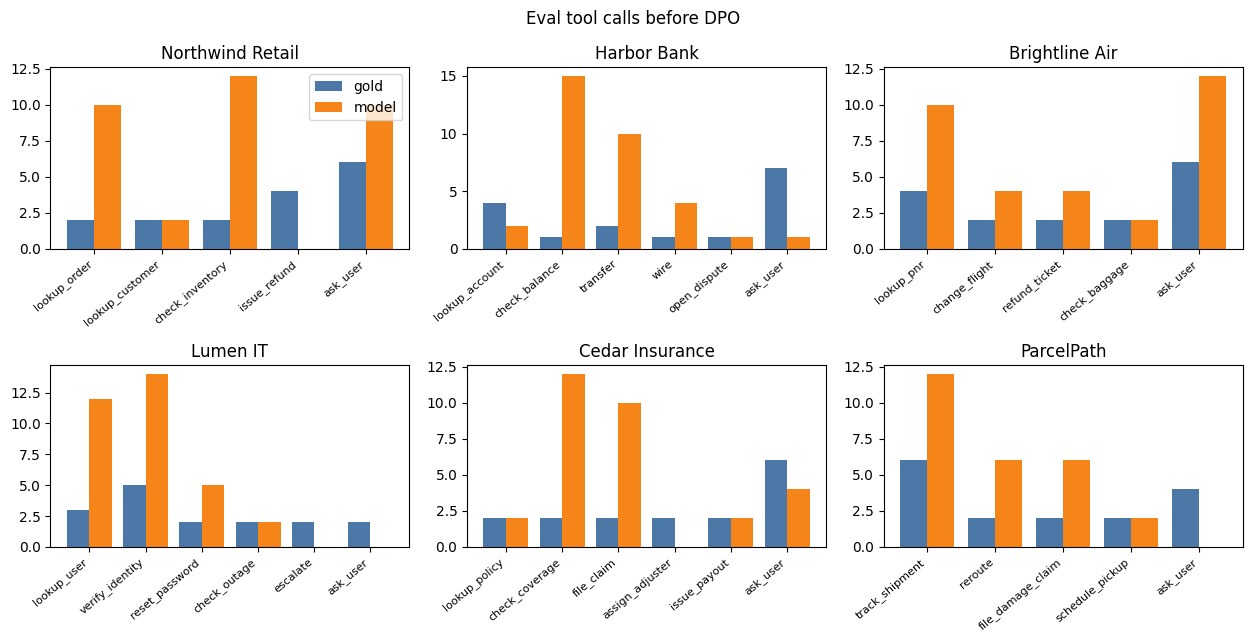


 northwind | Refund order Z910. Reason: arrived broken.
gold ['lookup_order'] | pred [] | outcome: empty
{
  "goal": "Refund order Z910 for arriving broken",
  "steps": [
    {
      "tool": "lookup_order",
      "args": {"order_id": "Z910"},
      "because": "To determine if the order exists and has been processed."
    },
    {
      "tool": "check_inventory",
      "args": {"sku": "broken_item_sku"},
      "because": "To verify if there are any remaining units available for the item that was suppo

 harbor | Transfer 40 USD from ACCT-910 to ACCT-980.
gold ['lookup_account'] | pred ['check_balance', 'transfer'] | outcome: policy
{
  "goal": "Transfer funds from one account to another",
  "steps": [
    {
      "tool": "check_balance",
      "args": {},
      "because": "To verify if there is enough balance to make the transfer."
    },
    {
      "tool": "transfer",
      "args": {"from_account": "ACCT-910", "to_account": "ACCT-980", "amount_usd": 40},
      "because": "To initiate

In [7]:
def load_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    return tokenizer


def load_base_model():
    kwargs = {"dtype": DTYPE}
    if DEVICE.type == "cuda":
        kwargs["device_map"] = "auto"
    return AutoModelForCausalLM.from_pretrained(MODEL_NAME, **kwargs)


def generate_plans_batched(model, tokenizer, rows, batch_size=BATCH_SIZE, label="eval"):
    model.eval()
    prompts = [
        tokenizer.apply_chat_template(
            messages_for(row["company"], row["user"], row["observations"]),
            tokenize=False,
            add_generation_prompt=True,
        )
        for row in rows
    ]
    outputs = []
    total = len(prompts)
    for start in range(0, total, batch_size):
        batch_prompts = prompts[start:start + batch_size]
        inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True)
        if DEVICE.type == "cuda":
            inputs = {key: value.to(model.device) for key, value in inputs.items()}
        input_len = inputs["input_ids"].shape[1]
        with torch.no_grad():
            gen = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
            )
        for seq in gen:
            outputs.append(tokenizer.decode(seq[input_len:], skip_special_tokens=True))
        print(f"[{label}] generated {min(start + batch_size, total)}/{total}", flush=True)
    return outputs


tokenizer = load_tokenizer()
base_model = load_base_model()
before_texts = generate_plans_batched(base_model, tokenizer, eval_rows, label="before DPO")

before_summary, before_gold, before_pred, before_scores = summarize(eval_rows, before_texts)
print_summary("Before DPO", before_summary)
plot_tool_counts(before_gold, before_pred, "Eval tool calls before DPO")

shown = set()
for row, text in zip(eval_rows, before_texts):
    if row["company"] in shown:
        continue
    shown.add(row["company"])
    score = tool_scores(row, text)
    print("\n", row["company"], "|", row["user"])
    print("gold", score["gold_tools"], "| pred", score["pred_tools"], "| outcome:", score["outcome"])
    print(text[:400])

del base_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("\nBaseline done.", len(eval_rows), "eval prompts")


## 5. DPO + LoRA training

$$
\mathcal{L}_{\text{DPO}}(\theta) = -\log \sigma\left(\beta\left[\log\frac{\pi_\theta(y^+|x)}{\pi_{\mathrm{ref}}(y^+|x)} - \log\frac{\pi_\theta(y^-|x)}{\pi_{\mathrm{ref}}(y^-|x)}\right]\right)
$$

LoRA ($r=16, \alpha=32$) on `q/k/v/o_proj` with `ref_model=None` (frozen base weights act as $\pi_{\mathrm{ref}}$).

In [12]:
def to_preference(row):
    return {
        "prompt": messages_for(row["company"], row["user"], row["observations"]),
        "chosen": [{"role": "assistant", "content": row["chosen"]}],
        "rejected": [{"role": "assistant", "content": row["rejected"]}],
    }


train_ds = Dataset.from_list([to_preference(row) for row in train_rows])
eval_ds = Dataset.from_list([to_preference(row) for row in eval_rows])

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)

training_args = DPOConfig(
    output_dir="./enterprise_dpo_checkpoints",
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=5e-5,
    num_train_epochs=2,
    lr_scheduler_type="cosine",
    beta=0.1,
    loss_type="sigmoid",
    max_length=1024,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="no",
    bf16=BF16,
    fp16=FP16,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    dataloader_num_workers=0,
    report_to="none",
    seed=SEED,
)

trainer = DPOTrainer(
    model=MODEL_NAME,
    ref_model=None,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=eval_ds,
    processing_class=tokenizer,
    peft_config=lora_config,
)
trainer.model.print_trainable_parameters()
train_result = trainer.train()
print(train_result)


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/540 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/540 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
1,0.002625,0.001164,0.173386,500751.000000,-2.195555,-2.155500,0.852678,0.050293,-11.366409,1.000000,11.416702,-87.310686,-214.827054
2,0.000646,0.000733,0.162694,1001502.000000,-2.211428,-2.169633,0.855030,-0.241943,-12.391041,1.000000,12.149099,-90.233047,-225.073376


TrainOutput(global_step=136, training_loss=0.05240402742107536, metrics={'train_runtime': 997.0993, 'train_samples_per_second': 1.083, 'train_steps_per_second': 0.136, 'total_flos': 8415565510582272.0, 'train_loss': 0.05240402742107536, 'epoch': 2.0})


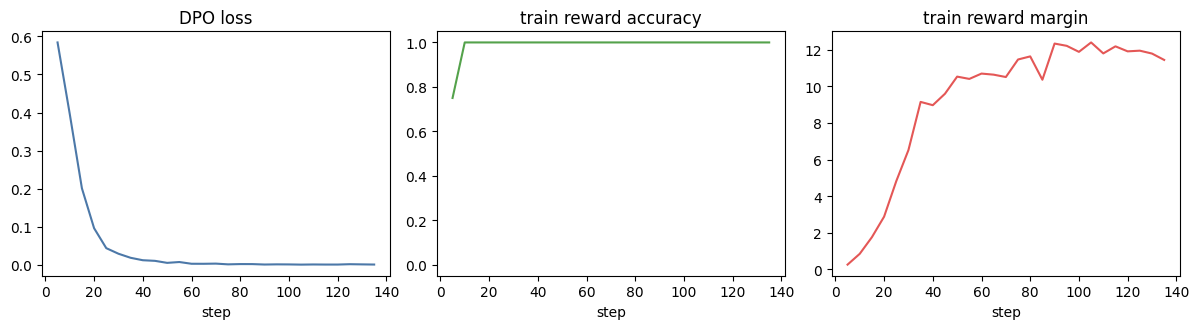

epoch 1.0 | eval accuracy 1.000 | eval margin 11.417
epoch 2.0 | eval accuracy 1.000 | eval margin 12.149


In [13]:
history = [row for row in trainer.state.log_history if "loss" in row or "rewards/accuracies" in row or "eval_rewards/accuracies" in row]

train_steps = [row["step"] for row in history if "loss" in row and "eval_loss" not in row]
train_loss = [row["loss"] for row in history if "loss" in row and "eval_loss" not in row]
train_acc = [row.get("rewards/accuracies") for row in history if "loss" in row and "eval_loss" not in row]
train_margin = [row.get("rewards/margins") for row in history if "loss" in row and "eval_loss" not in row]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(train_steps, train_loss, color="#4C78A8")
axes[0].set_title("DPO loss")
axes[0].set_xlabel("step")
axes[1].plot(train_steps, train_acc, color="#54A24B")
axes[1].set_title("train reward accuracy")
axes[1].set_xlabel("step")
axes[1].set_ylim(-0.05, 1.05)
axes[2].plot(train_steps, train_margin, color="#E45756")
axes[2].set_title("train reward margin")
axes[2].set_xlabel("step")
fig.tight_layout()
plt.show()

for row in trainer.state.log_history:
    if "eval_rewards/accuracies" not in row:
        continue
    print(
        f"epoch {row.get('epoch')} | eval accuracy {row['eval_rewards/accuracies']:.3f} "
        f"| eval margin {row.get('eval_rewards/margins', float('nan')):.3f}"
    )


## 6. Held-out evaluation (after DPO)

Same 96 prompts, decoder, and checker.

[after DPO] generated 8/96
[after DPO] generated 16/96
[after DPO] generated 24/96
[after DPO] generated 32/96
[after DPO] generated 40/96
[after DPO] generated 48/96
[after DPO] generated 56/96
[after DPO] generated 64/96
[after DPO] generated 72/96
[after DPO] generated 80/96
[after DPO] generated 88/96
[after DPO] generated 96/96
Before DPO
company        n   exact      f1   policy  wrong_seq  unground  illegal   empty
northwind     16    0.25    0.44     0.00       0.62      0.00     0.12    0.12
harbor        16    0.06    0.23     0.69       0.25      0.00     0.00    0.00
brightline    16    0.00    0.60     0.38       0.62      0.00     0.00    0.00
lumen         16    0.12    0.53     0.19       0.69      0.00     0.00    0.00
cedar         16    0.12    0.40     0.00       0.88      0.00     0.00    0.00
parcel        16    0.38    0.62     0.50       0.12      0.00     0.00    0.00
------------------------------------------------------------------------------
OVERALL       9

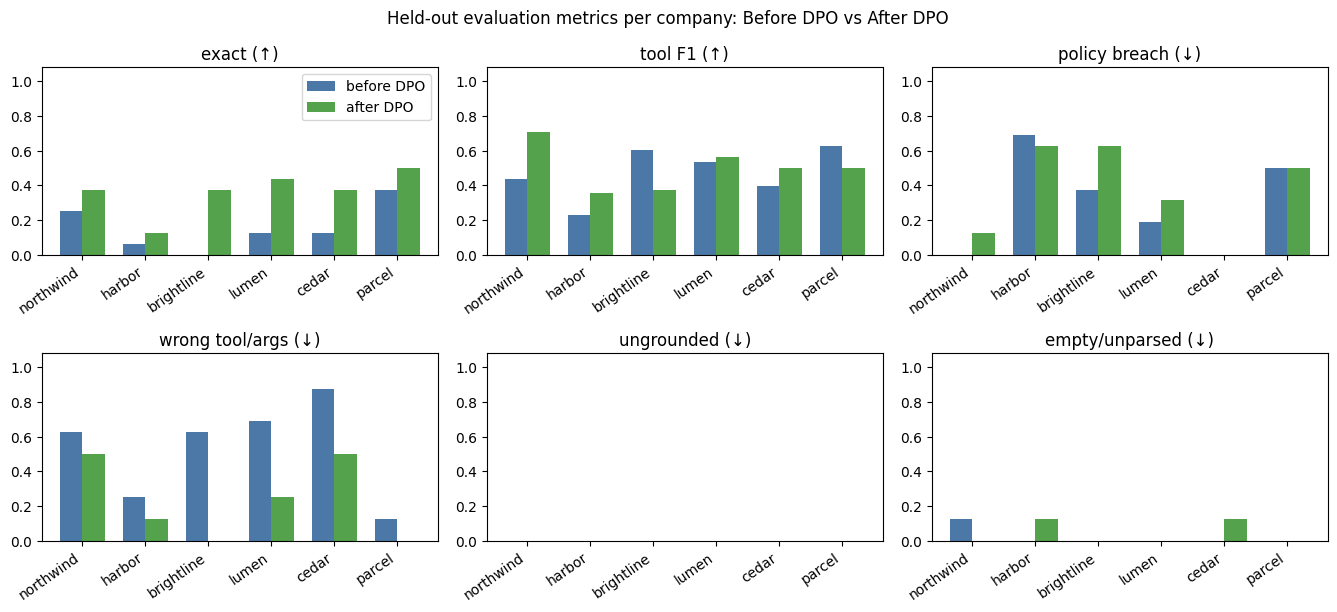

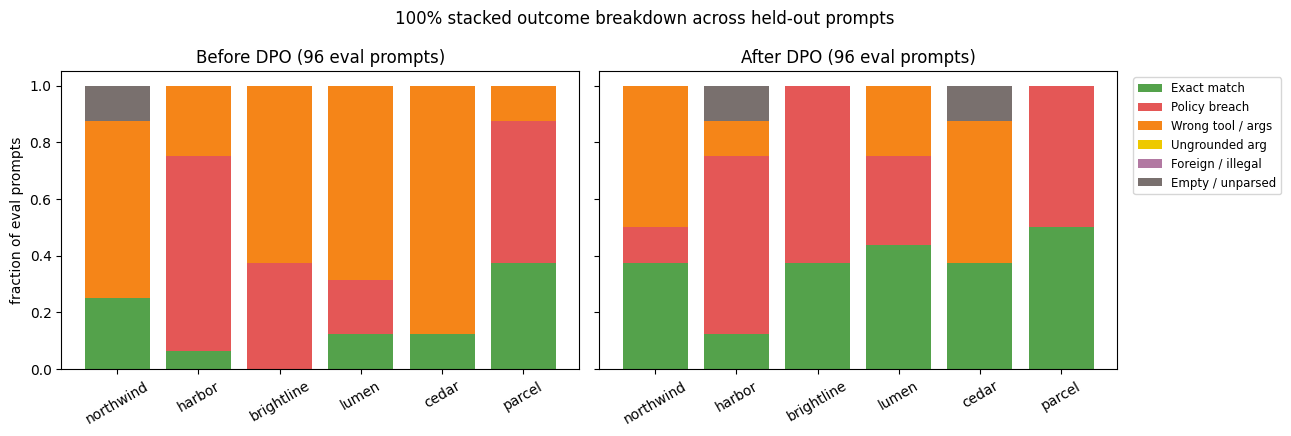

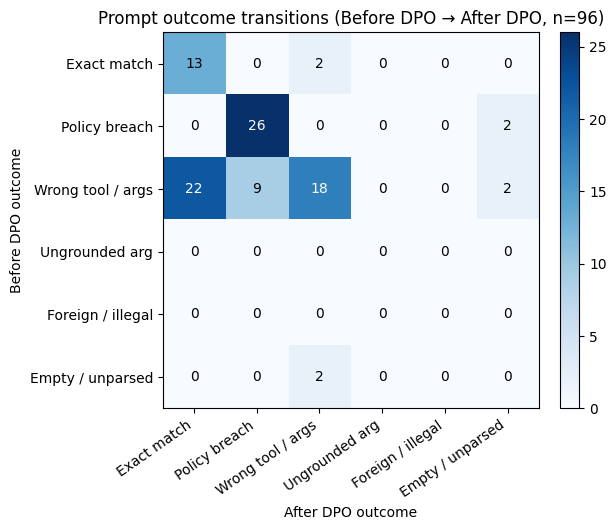

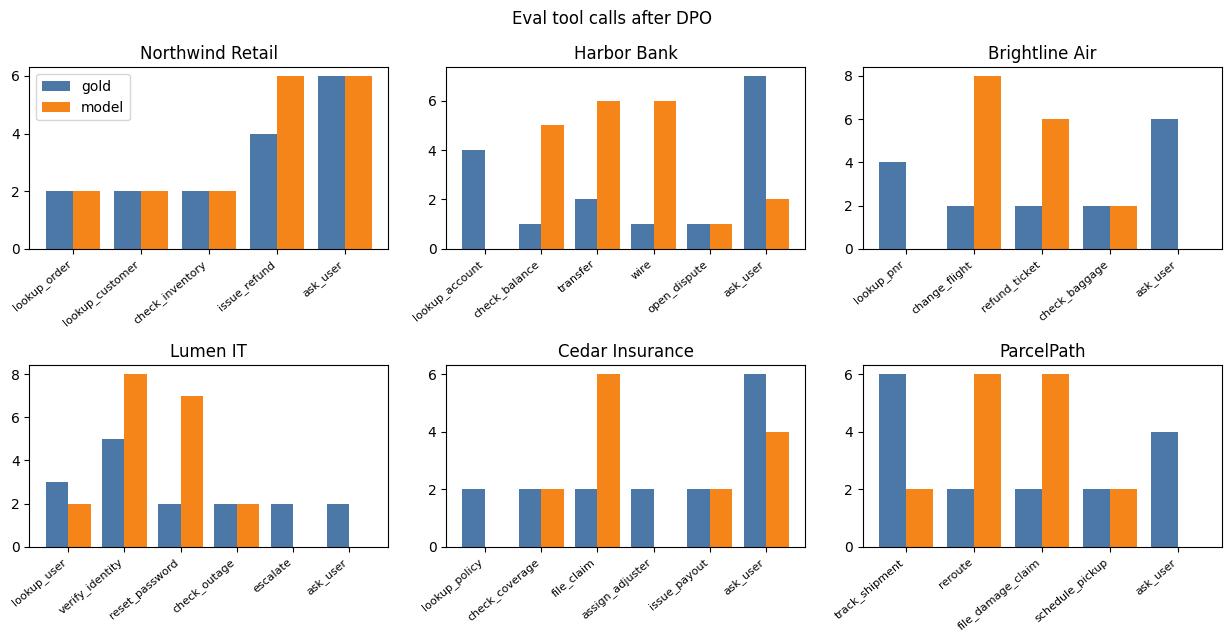


 northwind | Refund order Z910. Reason: arrived broken.
gold  : ['lookup_order']
before: [] (empty)
after : ['ask_user'] (wrong_seq)
{
  "goal": "refund order Z910",
  "steps": [
    {
      "tool": "ask_user",
      "args": {
        "question": "Order Z910 was refunded for reasons other than it being broken. Would you like to try again with a different reason?"
      },
      "because": "The observation does not show the order was broken, but rather another reason."
    }
  ],
  "stop_when": "Stop when the user provides a val

 harbor | Transfer 40 USD from ACCT-910 to ACCT-980.
gold  : ['lookup_account']
before: ['check_balance', 'transfer'] (policy)
after : [] (empty)
{
  "goal": "Transfer funds from the specified accounts.",
  "steps": [
    {
      "tool": "check_balance",
      "args": {
        "account_id": "ACCT-910"
      },
      "because": "The source account balance is needed for the transfer."
    },
    {
      "tool": "check_balance",
      "args": {
        "account_

In [14]:
after_texts = generate_plans_batched(trainer.model, tokenizer, eval_rows, label="after DPO")

after_summary, after_gold, after_pred, after_scores = summarize(eval_rows, after_texts)
print_summary("Before DPO", before_summary)
print()
print_summary("After DPO", after_summary)

plot_rates(before_summary, after_summary)
plot_outcome_breakdown(before_summary, after_summary)
plot_transition_matrix(before_scores, after_scores)
plot_tool_counts(after_gold, after_pred, "Eval tool calls after DPO")

shown = set()
for row, earlier, text in zip(eval_rows, before_texts, after_texts):
    if row["company"] in shown:
        continue
    shown.add(row["company"])
    before_score = tool_scores(row, earlier)
    after_score = tool_scores(row, text)
    print("\n", row["company"], "|", row["user"])
    print("gold  :", after_score["gold_tools"])
    print("before:", before_score["pred_tools"], f"({before_score['outcome']})")
    print("after :", after_score["pred_tools"], f"({after_score['outcome']})")
    print(text[:400])


In [ ]:
trainer.model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("saved", ADAPTER_DIR)

# Load later:
# from peft import PeftModel
# base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="auto")
# planner = PeftModel.from_pretrained(base, ADAPTER_DIR)
# texts = generate_plans_batched(planner, tokenizer, eval_rows)


## Notes

- Shared prefixes cancel in DPO: keeping `empty_steps` on the rejected side ensures non-zero gradient on opening `steps`.
- `rewards/accuracies` scores fixed pair strings; held-out greedy generation is what measures planning.